In [1]:
# parameter sweep
%run corg_train.py -m --multirun \
  model.hidden_layers=[64,32,16],[128,64,32] \
  model.dropout_rate=0.1,0.2,0.3 \
  training.batch_size=32,64 \
  training.learning_rate=0.0005,0.001,0.002 \
  spatial_weighting.method=density,kde \
  spatial_weighting.radius=0.15,0.2,0.25 \
  hydra.sweep.dir=./multirun/comprehensive_${now:%Y-%m-%d_%H-%M-%S} \
  hydra.sweep.subdir=run_${hydra:job.num}

[2026-06-05 17:04:57,593][HYDRA] Launching 216 jobs locally
[2026-06-05 17:04:57,593][HYDRA] 	#0 : model.hidden_layers=[64,32,16] model.dropout_rate=0.1 training.batch_size=32 training.learning_rate=0.0005 spatial_weighting.method=density spatial_weighting.radius=0.15
[2026-06-05 17:04:57,688][__main__][INFO] - Using device: cpu
[2026-06-05 17:04:57,697][__main__][INFO] - Missing values in training data:
[2026-06-05 17:04:57,698][__main__][INFO] - lon                   0
lat                   0
Corg (%)              0
mud (%)            1770
dist_coast (km)       0
depth (m)             0
[2026-06-05 17:04:57,701][__main__][INFO] - Calculating spatial weights using method: density
[2026-06-05 17:04:57,735][__main__][INFO] - Weight statistics:
[2026-06-05 17:04:57,736][__main__][INFO] -   Min weight: 0.100
[2026-06-05 17:04:57,736][__main__][INFO] -   Max weight: 3.000
[2026-06-05 17:04:57,736][__main__][INFO] -   Mean weight: 0.639
[2026-06-05 17:04:57,737][__main__][INFO] -   Std weig

Scanning runs for RMSE values...
Run 0: RMSE = 1.8712
Run 1: RMSE = 1.8370
Run 10: RMSE = 1.8731
Run 100: RMSE = 1.9064
Run 101: RMSE = 1.9064
Run 102: RMSE = 1.8542
Run 103: RMSE = 1.8104
Run 104: RMSE = 1.8297
Run 105: RMSE = 1.8747
Run 106: RMSE = 1.8747
Run 107: RMSE = 1.8747
Run 108: RMSE = 1.8168
Run 109: RMSE = 1.8390
Run 11: RMSE = 1.8731
Run 110: RMSE = 1.8311
Run 111: RMSE = 1.8493
Run 112: RMSE = 1.8493
Run 113: RMSE = 1.8493
Run 114: RMSE = 1.7942
Run 115: RMSE = 1.7971
Run 116: RMSE = 1.7981
Run 117: RMSE = 1.7794
Run 118: RMSE = 1.7794
Run 119: RMSE = 1.7794
Run 12: RMSE = 1.7822
Run 120: RMSE = 1.7713
Run 121: RMSE = 1.7710
Run 122: RMSE = 1.7452
Run 123: RMSE = 1.7623
Run 124: RMSE = 1.7623
Run 125: RMSE = 1.7623
Run 126: RMSE = 1.8275
Run 127: RMSE = 1.8232
Run 128: RMSE = 1.8728
Run 129: RMSE = 1.9174
Run 13: RMSE = 1.7627
Run 130: RMSE = 1.9174
Run 131: RMSE = 1.9174
Run 132: RMSE = 1.7806
Run 133: RMSE = 1.8006
Run 134: RMSE = 1.7994
Run 135: RMSE = 1.8797
Run 136: 

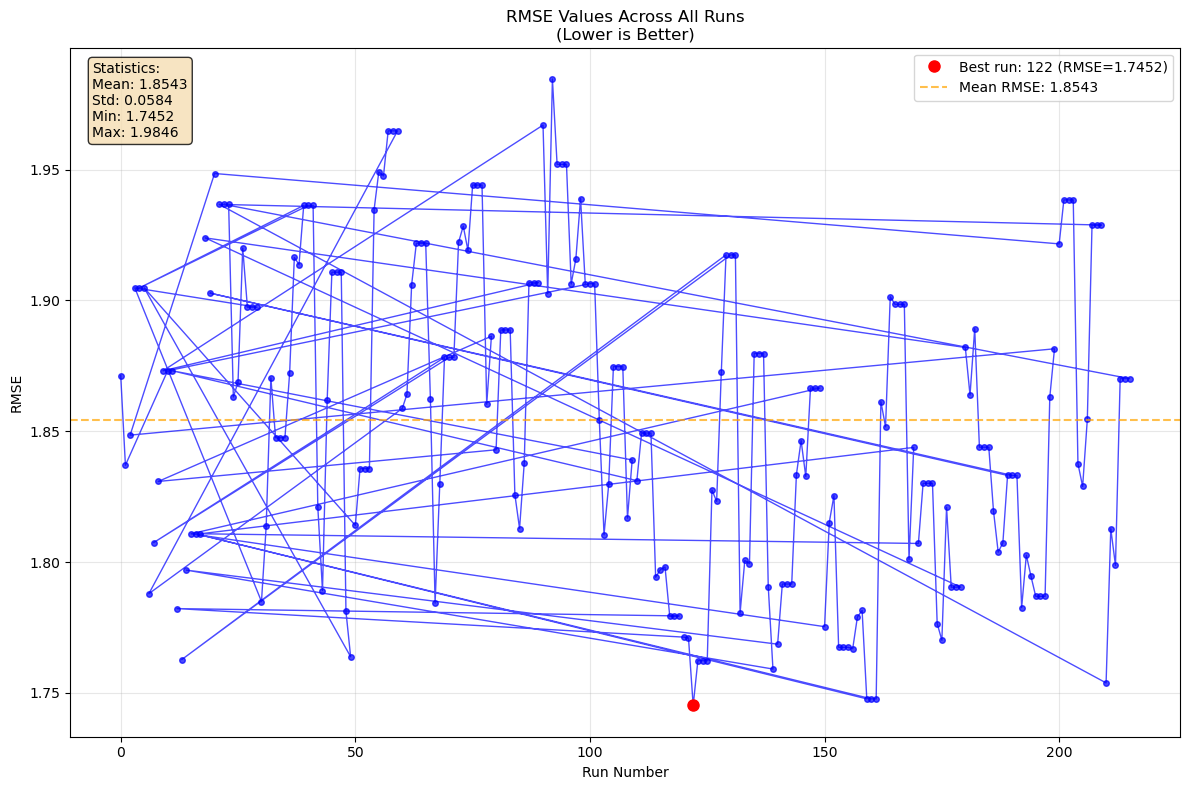


Top 5 best runs:
1. Run 122: RMSE = 1.7452
2. Run 161: RMSE = 1.7477
3. Run 160: RMSE = 1.7477
4. Run 159: RMSE = 1.7477
5. Run 210: RMSE = 1.7538


In [4]:
# find run with optimal parameters
%run find_best_run.py

In [5]:
# retrain with optimal parameters and full dataset
%run corg_train_full.py -m --multirun \
  model.hidden_layers=[128,64,32] \
  model.dropout_rate=0.1\
  training.batch_size=32 \
  training.learning_rate=0.002 \
  spatial_weighting.method=density \
  spatial_weighting.radius=0.25 \
  hydra.sweep.dir=./multirun/comprehensive_${now:%Y-%m-%d_%H-%M-%S} \
  hydra.sweep.subdir=run_${hydra:job.num}


[2026-06-05 20:39:52,155][HYDRA] Launching 1 jobs locally
[2026-06-05 20:39:52,155][HYDRA] 	#0 : model.hidden_layers=[128,64,32] model.dropout_rate=0.1 training.batch_size=32 training.learning_rate=0.002 spatial_weighting.method=density spatial_weighting.radius=0.25
[2026-06-05 20:39:52,254][__main__][INFO] - Using device: cpu
[2026-06-05 20:39:52,259][__main__][INFO] - Missing values in training data:
[2026-06-05 20:39:52,260][__main__][INFO] - lon                   0
lat                   0
Corg (%)              0
mud (%)            1770
dist_coast (km)       0
depth (m)             0
[2026-06-05 20:39:52,263][__main__][INFO] - Calculating spatial weights using method: density
[2026-06-05 20:39:52,311][__main__][INFO] - Weight statistics:
[2026-06-05 20:39:52,311][__main__][INFO] -   Min weight: 0.100
[2026-06-05 20:39:52,311][__main__][INFO] -   Max weight: 3.000
[2026-06-05 20:39:52,312][__main__][INFO] -   Mean weight: 0.441
[2026-06-05 20:39:52,312][__main__][INFO] -   Std weight

In [6]:
# run full prediction
%run corg_predict_nohydra.py

Using device: cpu


/home/g/g260124/corg-prediction_pub/corg/corg_predict_nohydra.py:34: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, map_location=

Predictions saved to outputs/corg_BS_out_pnts_500m_predictions_paramopt.csv
Map saved as plots/corg_prediction.png

Visualization value range:
Min value (1st percentile): 0.1970%
Max value (99th percentile): 10.0803%
Confidence visualization saved as plots/corg_confidence_map.png

Prediction Statistics:
Mean predicted Corg: 3.0488%
Mean prediction std: 0.5110%
Mean coefficient of variation: 0.2854
